# Customer Segmentation with K-Means Clustering

## From customer data to actionable customer segments

**Portfolio project | Unsupervised Machine Learning | Customer Analytics**

### Business problem

A marketing team has customer-level demographic, purchase, and digital-engagement data, but treating all customers as one population can hide important behavioral differences.

This project asks:

> **Can we identify distinct customer segments from demographic, spending, purchasing-channel, and digital-engagement behavior—and translate those segments into interpretable business profiles?**

The analysis is designed as a reproducible data-science workflow rather than a demonstration of a single clustering algorithm.

### What this project demonstrates

- Data-quality auditing and reproducible preprocessing
- Feature engineering for customer analytics
- Exploratory data analysis
- Distance-based unsupervised learning
- Model selection using **WCSS/Elbow** and **Silhouette Score**
- Cluster profiling and visualization
- PCA for visualization only
- Business-oriented interpretation of customer segments
- Explicit limitations and next-step recommendations


In [5]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 1. Data source and reproducibility

The original notebook reads the dataset from a Kaggle environment. To make the project easier to reproduce locally, keep the CSV in a `data/` directory and change `DATA_PATH` if necessary.

**Important:** the dataset itself is not embedded in this repository by default. Add it locally according to its licensing/source requirements.


In [6]:
df = pd.read_csv('customer_segmentation.csv')
print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,"26,646.00",1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,"58,293.00",1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. Data audit

Before modeling, inspect:

- dataset dimensions
- data types
- missing values
- duplicate customer records
- suspicious ranges and extreme observations

This step is important because K-Means is distance-based: unusual observations can influence cluster centroids substantially.


In [7]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe().T)


Shape: (2240, 29)

Data types:


,dtype
ID,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64



Missing values:


,missing_count
Income,24



Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
ID,"2,240.00","5,592.16","3,246.66",0.00,"2,828.25","5,458.50","8,427.75","11,191.00"
Year_Birth,"2,240.00","1,968.81",11.98,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00"
Income,"2,216.00","52,247.25","25,173.08","1,730.00","35,303.00","51,381.50","68,522.00","666,666.00"
Kidhome,"2,240.00",0.44,0.54,0.00,0.00,0.00,1.00,2.00
Teenhome,"2,240.00",0.51,0.54,0.00,0.00,0.00,1.00,2.00
Recency,"2,240.00",49.11,28.96,0.00,24.00,49.00,74.00,99.00
MntWines,"2,240.00",303.94,336.60,0.00,23.75,173.50,504.25,"1,493.00"
MntFruits,"2,240.00",26.30,39.77,0.00,1.00,8.00,33.00,199.00
MntMeatProducts,"2,240.00",166.95,225.72,0.00,16.00,67.00,232.00,"1,725.00"
MntFishProducts,"2,240.00",37.53,54.63,0.00,3.00,12.00,50.00,259.00


### Data-quality findings

The original dataset contains **2,240 records and 29 variables**, with missing values in `Income`.

Two observations require explicit treatment:

1. `Year_Birth` contains an extreme historical value (`1893`), which would imply an implausible age if converted directly to a modern age.
2. `Income` contains an extreme value (`666666`) relative to the rest of the distribution.

Rather than silently letting these values affect a distance-based model, the project flags them as potential data-quality outliers and performs the clustering analysis on a quality-controlled modeling sample.

The excluded observations should be reviewed against the original data source before operational use.


In [8]:
# Inspect the main suspicious observations
print("Very early birth years:")
display(df.loc[df["Year_Birth"] < 1940, ["ID", "Year_Birth", "Income"]])

print("Very high income values:")
display(df.loc[df["Income"] > 200000, ["ID", "Year_Birth", "Income"]])


Very early birth years:


,ID,Year_Birth,Income
192,7829,1900,"36,640.00"
239,11004,1893,"60,182.00"
339,1150,1899,"83,532.00"


Very high income values:


,ID,Year_Birth,Income
2233,9432,1977,"666,666.00"


## 3. Data preparation and feature engineering

### Reproducibility decision

The original notebook calculated customer tenure using `pd.Timestamp('today')`. That makes the same notebook produce different values on different days.

Instead, a fixed reference date is used. The date is chosen as a modeling convention and can be changed if the business has a documented analysis date.

### Engineered features

- **Age**: reference year minus birth year
- **Total_Children**: children at home + teenagers at home
- **Total_Spending**: spending across six product categories
- **AcceptedAny**: whether the customer accepted at least one campaign
- **Customer_Since**: days from registration to a fixed reference date

Only features relevant to segmentation are used in the final clustering model.


In [9]:
df = df.copy()

# Parse dates
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce")

# Median imputation for the 24 missing Income values
df["Income"] = df["Income"].fillna(df["Income"].median())

# Fixed reference date for reproducibility
REFERENCE_DATE = pd.Timestamp("2014-12-31")
REFERENCE_YEAR = REFERENCE_DATE.year

df["Age"] = REFERENCE_YEAR - df["Year_Birth"]
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

spent_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
df["Total_Spending"] = df[spent_cols].sum(axis=1)

campaign_cols = [
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
    "AcceptedCmp4", "AcceptedCmp5", "Response"
]
df["AcceptedAny"] = (df[campaign_cols].sum(axis=1) > 0).astype(int)

df["Customer_Since"] = (REFERENCE_DATE - df["Dt_Customer"]).dt.days

display(df[[
    "ID", "Age", "Income", "Total_Children",
    "Total_Spending", "AcceptedAny", "Customer_Since"
]].head())


,ID,Age,Income,Total_Children,Total_Spending,AcceptedAny,Customer_Since
0,5524,57,"58,138.00",0,1617,1,848
1,2174,60,"46,344.00",2,27,0,298
2,4141,49,"71,613.00",0,776,0,497
3,6182,30,"26,646.00",1,53,0,324
4,5324,33,"58,293.00",1,422,0,346


## 4. Define the modeling population

For the clustering model, extreme values are excluded from the **modeling sample** rather than deleted from the raw dataset.

This keeps the original data available for audit while preventing clearly suspicious observations from disproportionately affecting Euclidean distances.

The thresholds below are **data-quality rules for this project**, not universal business rules.


In [10]:
model_df = df[
    df["Year_Birth"].between(1940, 1996)
    & df["Income"].le(200000)
].copy()

print(f"Original observations: {len(df):,}")
print(f"Modeling observations: {len(model_df):,}")
print(f"Excluded for data-quality review: {len(df) - len(model_df):,}")


Original observations: 2,240
Modeling observations: 2,236
Excluded for data-quality review: 4


## 5. Exploratory Data Analysis

The goal of EDA is not simply to create plots. It is to understand which variables may separate customers and identify relationships that should influence feature selection.

We examine:

- income and spending distributions
- correlation among behavioral variables
- spending by education and marital-status groups
- campaign response behavior


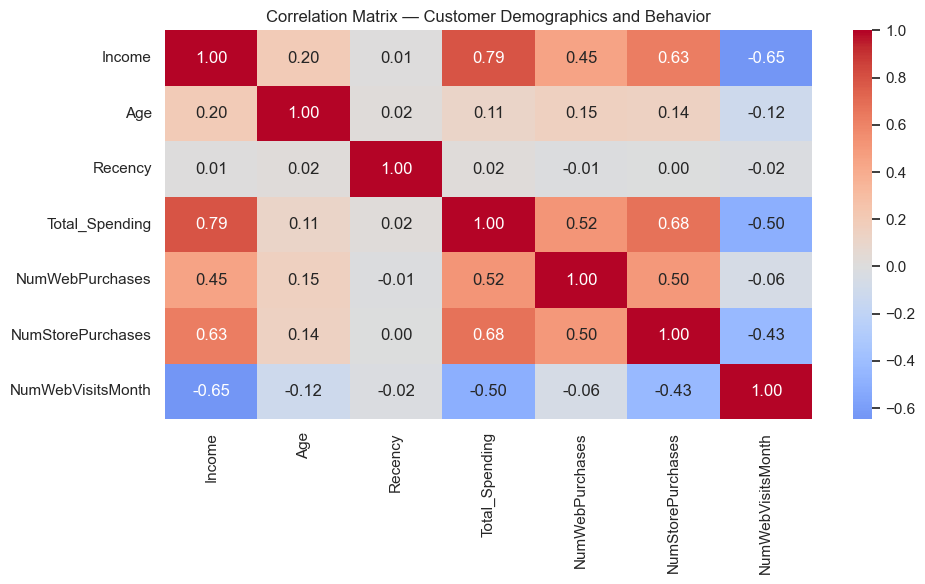

In [11]:
eda_cols = [
    "Income", "Age", "Recency", "Total_Spending",
    "NumWebPurchases", "NumStorePurchases", "NumWebVisitsMonth"
]

plt.figure(figsize=(10, 6))
sns.heatmap(model_df[eda_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix — Customer Demographics and Behavior")
plt.tight_layout()
plt.show()


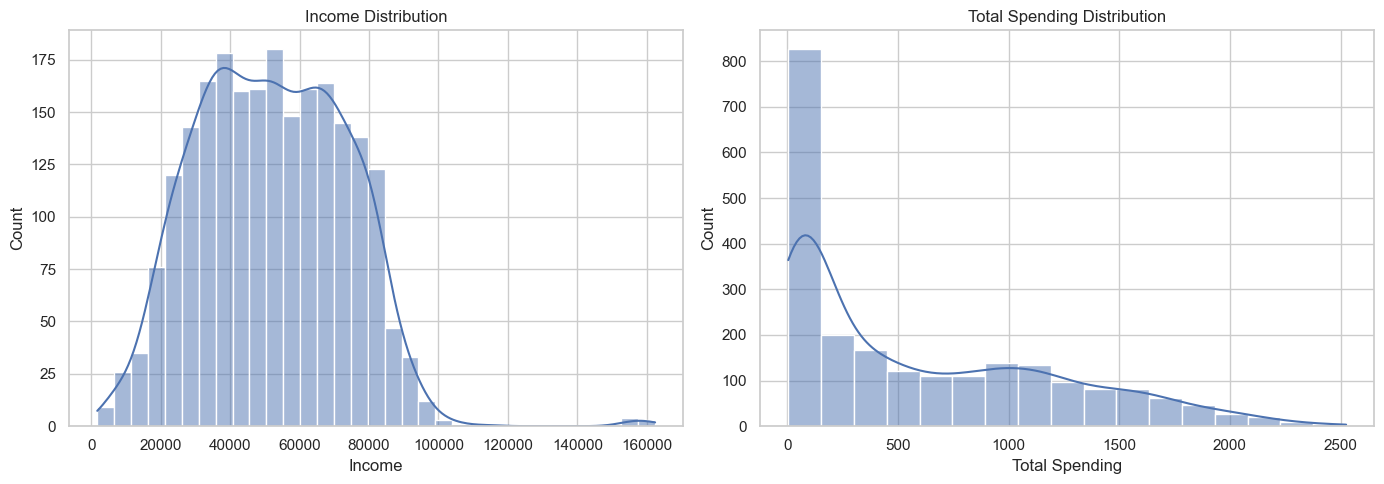

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(model_df["Income"], kde=True, ax=axes[0])
axes[0].set_title("Income Distribution")
axes[0].set_xlabel("Income")

sns.histplot(model_df["Total_Spending"], kde=True, ax=axes[1])
axes[1].set_title("Total Spending Distribution")
axes[1].set_xlabel("Total Spending")

plt.tight_layout()
plt.show()


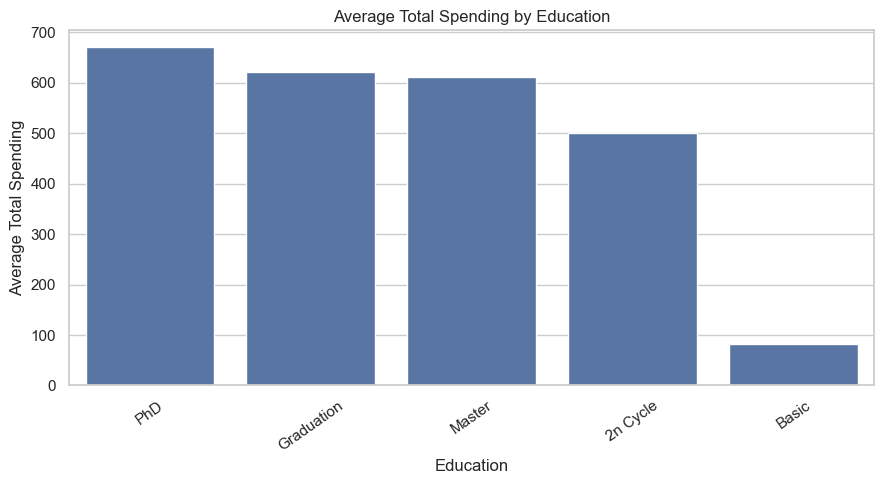

,Average_Total_Spending
Education,
PhD,669.98
Graduation,620.39
Master,611.78
2n Cycle,501.03
Basic,81.80


In [13]:
education_spending = (
    model_df.groupby("Education", observed=True)["Total_Spending"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=education_spending.index, y=education_spending.values)
plt.title("Average Total Spending by Education")
plt.xlabel("Education")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(education_spending.to_frame("Average_Total_Spending"))


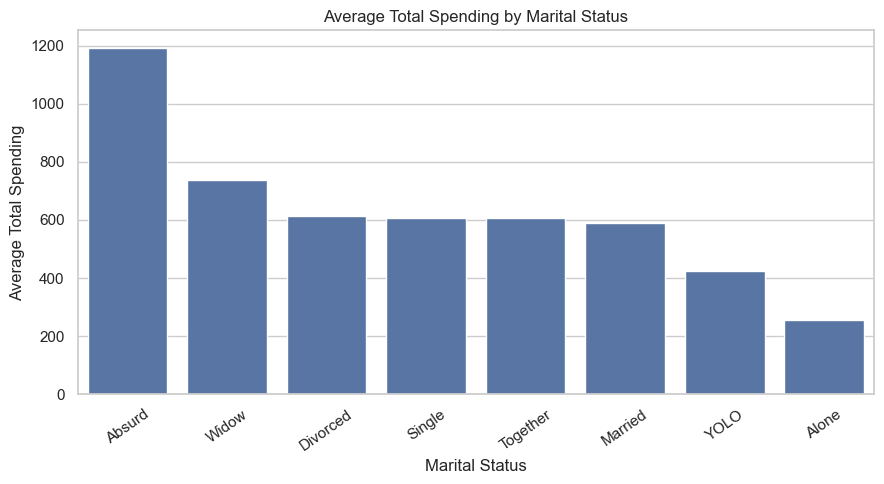

In [14]:
marital_spending = (
    model_df.groupby("Marital_Status", observed=True)["Total_Spending"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=marital_spending.index, y=marital_spending.values)
plt.title("Average Total Spending by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


## 6. Feature selection

The clustering features are chosen to represent three customer dimensions:

| Dimension | Features |
|---|---|
| Customer profile | `Age`, `Income` |
| Economic value / purchasing | `Total_Spending` |
| Channel behavior | `NumWebPurchases`, `NumStorePurchases` |
| Digital engagement | `NumWebVisitsMonth` |

Campaign-response variables are kept for **post-clustering analysis** rather than used to define the clusters. This avoids making campaign response itself part of the segmentation definition.


In [15]:
features = [
    "Age",
    "Income",
    "Total_Spending",
    "NumWebPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

X = model_df[features].copy()
display(X.describe().T)


,count,mean,std,min,25%,50%,75%,max
Age,"2,236.00",45.10,11.70,18.00,37.00,44.00,55.00,74.00
Income,"2,236.00","51,952.61","21,411.47","1,730.00","35,502.50","51,381.50","68,275.75","162,397.00"
Total_Spending,"2,236.00",605.99,601.87,5.00,69.00,396.50,"1,045.50","2,525.00"
NumWebPurchases,"2,236.00",4.09,2.78,0.00,2.00,4.00,6.00,27.00
NumStorePurchases,"2,236.00",5.80,3.25,0.00,3.00,5.00,8.00,13.00
NumWebVisitsMonth,"2,236.00",5.32,2.43,0.00,3.00,6.00,7.00,20.00


## 7. Feature scaling

K-Means uses Euclidean distance. Income and spending therefore cannot be allowed to dominate simply because they have larger numerical scales.

Standardization transforms each feature to approximately zero mean and unit variance before clustering.


In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)
display(X_scaled_df.head())


,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth
0,1.02,0.29,1.68,1.41,-0.55,0.69
1,1.27,-0.26,-0.96,-1.11,-1.17,-0.13
2,0.33,0.92,0.28,1.41,1.29,-0.54
3,-1.29,-1.18,-0.92,-0.75,-0.55,0.28
4,-1.03,0.30,-0.31,0.33,0.06,-0.13


## 8. Choosing the number of clusters

There is no universally correct value of `K`.

This project evaluates candidate values using:

### WCSS / Elbow
Measures within-cluster dispersion. Increasing `K` always reduces WCSS, so the goal is to identify a useful point of diminishing returns.

### Silhouette Score
Measures how similar observations are to their own cluster compared with neighboring clusters. Higher values generally indicate better-separated clusters.

Both metrics are considered together rather than relying on a single heuristic.


In [17]:
k_values = range(2, 11)
wcss = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )
    labels = model.fit_predict(X_scaled)
    wcss.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

evaluation = pd.DataFrame({
    "K": list(k_values),
    "WCSS": wcss,
    "Silhouette_Score": silhouette_scores
})

display(evaluation)


,K,WCSS,Silhouette_Score
0,2,"7,760.02",0.38
1,3,"6,524.99",0.32
2,4,"5,749.21",0.24
3,5,"5,165.26",0.24
4,6,"4,795.67",0.23
5,7,"4,527.14",0.23
6,8,"4,289.36",0.23
7,9,"4,069.85",0.23
8,10,"3,881.59",0.21


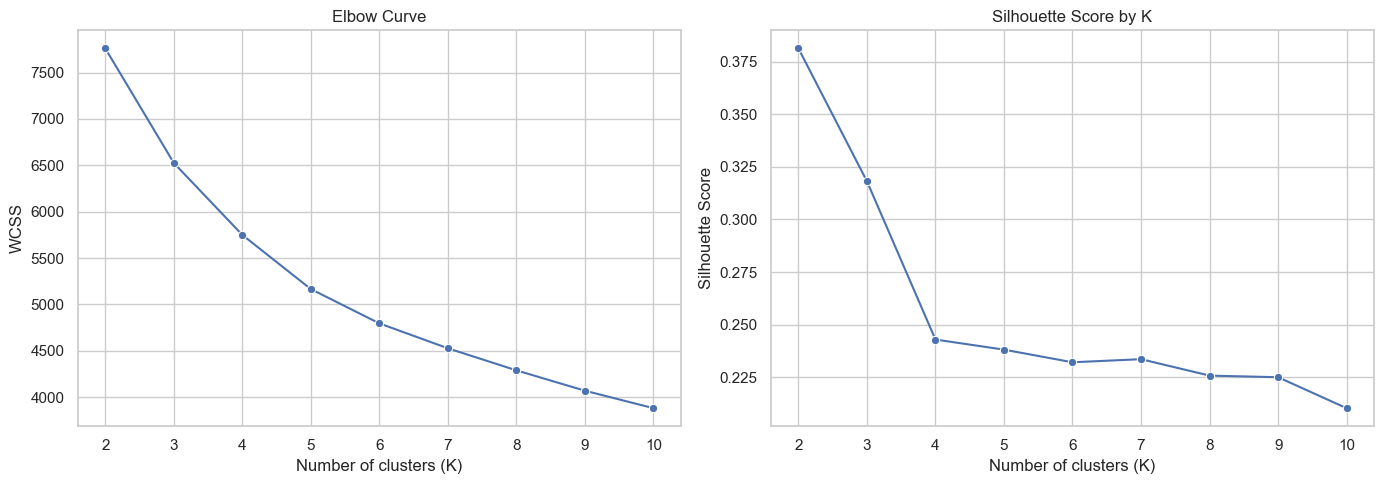

Highest-silhouette K: 2


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=evaluation, x="K", y="WCSS", marker="o", ax=axes[0])
axes[0].set_title("Elbow Curve")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("WCSS")

sns.lineplot(data=evaluation, x="K", y="Silhouette_Score", marker="o", ax=axes[1])
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_silhouette_k = int(
    evaluation.loc[evaluation["Silhouette_Score"].idxmax(), "K"]
)
print("Highest-silhouette K:", best_silhouette_k)


### Modeling decision

The original analysis identified **K = 5** using the elbow analysis. The revised notebook also reports the silhouette scores so the choice can be assessed quantitatively.

For comparability with the original project, the final model uses **5 clusters**. If the recomputed evaluation shows that another `K` is materially better, that should be discussed rather than hidden.


In [19]:
N_CLUSTERS = 5

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

model_df["Cluster"] = kmeans.fit_predict(X_scaled)

final_silhouette = silhouette_score(
    X_scaled,
    model_df["Cluster"]
)

print(f"Final number of clusters: {N_CLUSTERS}")
print(f"Final silhouette score: {final_silhouette:.3f}")


Final number of clusters: 5
Final silhouette score: 0.238


## 9. Cluster size and profile

Cluster IDs are arbitrary numerical labels. A cluster numbered `4` is not inherently better or worse than cluster `1`.

The useful question is:

> **What characteristics distinguish each segment?**


In [20]:
cluster_counts = model_df["Cluster"].value_counts().sort_index()
cluster_distribution = pd.DataFrame({
    "Customers": cluster_counts,
    "Share_%": (cluster_counts / len(model_df) * 100).round(2)
})

display(cluster_distribution)


,Customers,Share_%
Cluster,,
0,339,15.16
1,676,30.23
2,341,15.25
3,436,19.50
4,444,19.86


In [21]:
cluster_profile = (
    model_df.groupby("Cluster")[features]
    .mean()
    .round(2)
)

display(cluster_profile)


,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth
Cluster,,,,,,
0,58.18,"73,360.74","1,204.40",4.73,8.65,2.82
1,36.23,"30,760.28",94.86,2.13,3.04,7.01
2,35.10,"76,071.45","1,295.24",4.65,8.57,2.70
3,54.21,"42,595.16",156.25,2.44,3.86,5.53
4,47.36,"58,538.18",839.56,7.76,7.59,6.46


In [22]:
# Compare cluster means with the overall population.
overall_means = model_df[features].mean()

cluster_index = (
    cluster_profile
    .div(overall_means)
    .mul(100)
    .round(1)
)

display(cluster_index)


,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth
Cluster,,,,,,
0,129.00,141.20,198.80,115.70,149.30,53.00
1,80.30,59.20,15.70,52.10,52.50,131.80
2,77.80,146.40,213.70,113.80,147.90,50.80
3,120.20,82.00,25.80,59.70,66.60,104.00
4,105.00,112.70,138.50,189.80,131.00,121.50


### Reading the cluster index

The cluster-index table expresses each cluster's average as a percentage of the overall modeling population average.

- `100` = approximately the overall average
- `>100` = above the overall average
- `<100` = below the overall average

This is often easier for a business audience to interpret than raw averages alone.


## 10. Customer segment interpretation

The original clustering results suggest five distinct behavioral profiles. The labels below are descriptive personas derived from the cluster averages; they are **not ground-truth customer classes**.

The final notebook should use the recomputed `cluster_profile` table above as the source of truth if preprocessing or the dataset changes.


In [23]:
# Automatically create a compact profile table for review.
profile = cluster_profile.copy()
profile["Customers"] = cluster_counts
profile["Share_%"] = cluster_distribution["Share_%"]

display(profile.sort_values("Total_Spending", ascending=False))


,Age,Income,Total_Spending,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth,Customers,Share_%
Cluster,,,,,,,,
2,35.10,"76,071.45","1,295.24",4.65,8.57,2.70,341,15.25
0,58.18,"73,360.74","1,204.40",4.73,8.65,2.82,339,15.16
4,47.36,"58,538.18",839.56,7.76,7.59,6.46,444,19.86
3,54.21,"42,595.16",156.25,2.44,3.86,5.53,436,19.50
1,36.23,"30,760.28",94.86,2.13,3.04,7.01,676,30.23


### Potential business interpretation framework

Use the following dimensions when naming segments:

- **Customer value:** Total Spending + Income
- **Channel preference:** Web vs Store Purchases
- **Digital engagement:** Web Visits
- **Life stage:** Age

For example, a segment with high income, high spending, and high store purchases can be described as a **high-value store-oriented segment**. A segment with low spending and low purchase activity can be described as a **lower-engagement segment**.

Avoid treating these labels as causal explanations. Clustering identifies similarity; it does not prove why customers behave differently.


## 11. PCA visualization

PCA is used here **only for visualization**.

The model itself was trained on the standardized six-dimensional feature space. Reducing the data to two principal components can help us visually inspect whether the resulting groups are reasonably separated.


In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_data = pca.fit_transform(X_scaled)

model_df["PCA1"] = pca_data[:, 0]
model_df["PCA2"] = pca_data[:, 1]

explained_variance = pca.explained_variance_ratio_

print(f"PC1 explained variance: {explained_variance[0]:.2%}")
print(f"PC2 explained variance: {explained_variance[1]:.2%}")
print(f"Combined explained variance: {explained_variance.sum():.2%}")


PC1 explained variance: 53.17%
PC2 explained variance: 16.50%
Combined explained variance: 69.67%


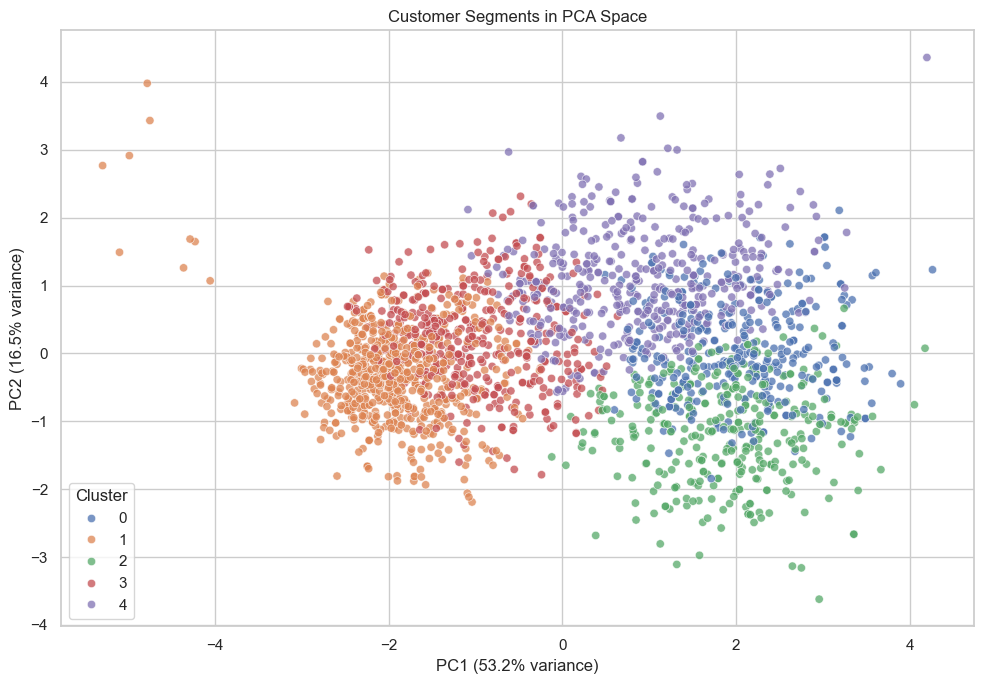

In [25]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=model_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="deep",
    alpha=0.75
)
plt.title("Customer Segments in PCA Space")
plt.xlabel(f"PC1 ({explained_variance[0]:.1%} variance)")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%} variance)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


## 12. Post-clustering campaign analysis

Campaign response was deliberately not used to define the clusters. It can therefore be used as a supplementary variable to investigate whether campaign behavior differs across the discovered segments.

This is an important distinction:

> **Segmentation describes customer similarity; campaign response can then be evaluated across those segments.**

It does not establish that a segment causes a customer to respond.


In [26]:
campaign_by_cluster = (
    model_df.groupby("Cluster")
    .agg(
        Customers=("ID", "count"),
        Campaign_Acceptance_Rate=("AcceptedAny", "mean"),
        Average_Spending=("Total_Spending", "mean"),
        Average_Income=("Income", "mean"),
        Average_Web_Purchases=("NumWebPurchases", "mean"),
        Average_Store_Purchases=("NumStorePurchases", "mean")
    )
)

campaign_by_cluster["Campaign_Acceptance_Rate"] *= 100
campaign_by_cluster = campaign_by_cluster.round(2)

display(campaign_by_cluster)


,Customers,Campaign_Acceptance_Rate,Average_Spending,Average_Income,Average_Web_Purchases,Average_Store_Purchases
Cluster,,,,,,
0,339,40.41,"1,204.40","73,360.74",4.73,8.65
1,676,16.57,94.86,"30,760.28",2.13,3.04
2,341,42.23,"1,295.24","76,071.45",4.65,8.57
3,436,12.84,156.25,"42,595.16",2.44,3.86
4,444,35.81,839.56,"58,538.18",7.76,7.59


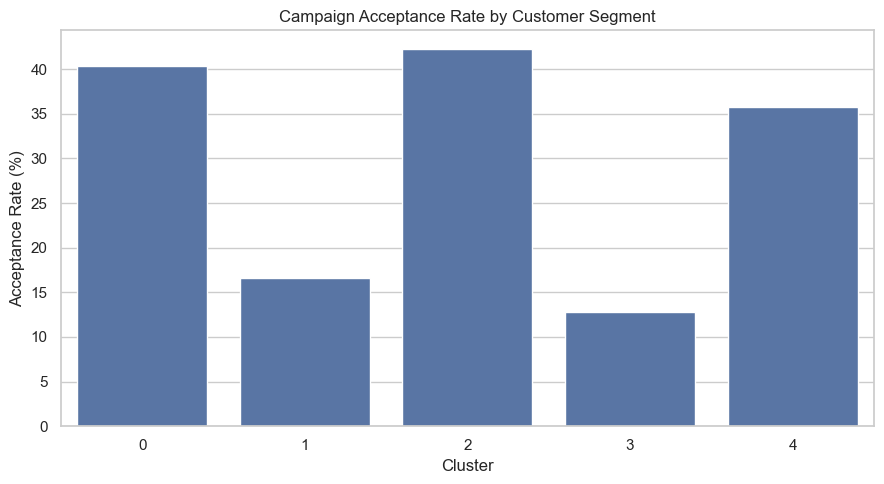

In [27]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=campaign_by_cluster.reset_index(),
    x="Cluster",
    y="Campaign_Acceptance_Rate"
)
plt.title("Campaign Acceptance Rate by Customer Segment")
plt.ylabel("Acceptance Rate (%)")
plt.xlabel("Cluster")
plt.tight_layout()
plt.show()


## 13. Business recommendations

The segmentation can support **hypothesis-driven** marketing actions.

| Segment characteristic | Potential action to test |
|---|---|
| High value + high spending | Retention, loyalty, premium-product campaigns |
| High value + store-oriented | In-store promotions and personalized offers |
| High digital engagement + moderate spending | Test digital cross-sell and conversion campaigns |
| Low spending + low engagement | Test low-cost reactivation offers |
| Older high-value customers | Test retention and convenience-focused communication |

These are proposed actions to test, not claims that the clustering proves a particular strategy will increase revenue.

A production marketing system should validate interventions using controlled experiments or uplift modeling.


## 14. Final takeaways

This project demonstrates an end-to-end unsupervised learning workflow:

**Raw customer data → data audit → feature engineering → EDA → scaling → K selection → K-Means → cluster profiling → PCA visualization → business hypotheses**

The most important portfolio lesson is not simply that K-Means can create five clusters. It is that a data scientist must make the full chain of decisions **reproducible, measurable, interpretable, and connected to a business question**.
